# Lista 1 – Regressão Linear Múltipla

**0. Preparação do ambiente**

**1. Exercício 1 – Propagandas:** modelo de regressão múltipla para predizer as vendas (`Propagandas.csv`)
- 1.1. Análise descritiva
- 1.2. Correlação e covariância
- 1.3. Modelo de regressão
- 1.4. Análise de resíduos
- 1.5. Análise de multicolinearidade
- 1.6. Análise do modelo

**2. Exercício 2 – Preços de carros:** três modelos de regressão múltipla para predizer o preço dos automóveis (`Preços_Carros.csv`)
- 2.1. Análise descritiva
- 2.2. Correlação e covariância
- 2.3. Modelos de regressão
- 2.4. Análise de resíduos
- 2.5. Análise de multicolinearidade
- 2.6. Análise de outliers
- 2.7. Comparação de modelos

## 0. Preparação do ambiente

> **Objetivo:** importar as bibliotecas usadas no notebook.

In [58]:
# Importação das bibliotecas necessárias
import numpy as np # Para operações numéricas
import pandas as pd # Para manipulação de dados em DataFrame
import matplotlib.pyplot as plt # Para criação de gráficos
import seaborn as sns # Para visualização de dados estatísticos
import statsmodels.api as sm # Para modelos estatísticos, incluindo regressão linear (OLS)
from scipy import stats # Para funções estatísticas, incluindo testes de normalidade (Shapiro-Wilk)
from statsmodels.stats.diagnostic import het_breuschpagan # Teste de Breusch-Pagan para homocedasticidade

sns.set_theme(style='whitegrid')

## 1. Exercício 1 – Propagandas

> **Objetivo:** predizer `Vendas` a partir do investimento em `TV`, `Radio` e `Jornal`.

### 1.1. Análise descritiva

> **Objetivo:** conhecer os dados antes de modelar.

#### 1.1.1. Carregamento dos dados

> **Objetivo:** carregar a base e ver como ela se apresenta.

In [23]:
propagandas = pd.read_csv('../data/Propagandas.csv')

Visualização das 5 primeiras linhas

In [24]:
propagandas.head()

,TV,Radio,Jornal,Vendas
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


OBSERVAÇÕES

Vemos que cada linha traz o investimento em três tipos de mídia e suas respectivas vendas; as unidades não são informadas.

#### 1.1.2. Dimensão da base de dados e tipo das variáveis

> **Objetivo:** saber o tamanho da base e se os tipos estão adequados.

In [25]:
print(f"Observações: {propagandas.shape[0]} | Variáveis: {propagandas.shape[1]}")
propagandas.dtypes

Observações: 200 | Variáveis: 4


TV        float64
Radio     float64
Jornal    float64
Vendas    float64
dtype: object

OBSERVAÇÕES

São 200 observações com 3 variáveis (features) e um alvo (Vendas), todos float64, tudo devidamente formatado, nenhuma intervenção é necessária.

#### 1.1.3. Verificação de valores ausentes e linhas duplicadas

> **Objetivo:** verificar se a base precisa de limpeza.

In [26]:
print(f"Linhas duplicadas: {propagandas.duplicated().sum()}")
propagandas.isnull().sum()

Linhas duplicadas: 0


TV        0
Radio     0
Jornal    0
Vendas    0
dtype: int64

OBSERVAÇÕES

Zero observações duplicadas ou com dados ausentes, nenhuma intervenção é necessária.

#### 1.1.4. Medidas de tendência central, dispersão e forma

> **Objetivo:** resumir em números o centro, a dispersão e a assimetria de cada variável.

In [27]:
resumo = propagandas.describe().T
resumo['CV (%)'] = propagandas.std() / propagandas.mean() * 100
resumo['assimetria'] = propagandas.skew()
resumo.round(2)

,count,mean,std,min,25%,50%,75%,max,CV (%),assimetria
TV,200.0,147.04,85.85,0.7,74.38,149.75,218.82,296.4,58.39,-0.07
Radio,200.0,23.26,14.85,0.0,9.98,22.90,36.52,49.6,63.82,0.09
Jornal,200.0,30.55,21.78,0.3,12.75,25.75,45.10,114.0,71.28,0.89
Vendas,200.0,14.02,5.22,1.6,10.38,12.90,17.40,27.0,37.21,0.41


OBSERVAÇÕES

1. TV é uma distribuição quase simétrica.
2. Radio também, quase simétrica.
3. Jornal possui uma cauda à direita, com alguns valores mais altos que puxam a média.
4. Vendas, assim como Jornal, possui cauda à direita, porém bem menor.

#### 1.1.5. Comparação do coeficiente de variação

> **Objetivo:** comparar a dispersão relativa de variáveis com médias diferentes (CV = desvio padrão / média).

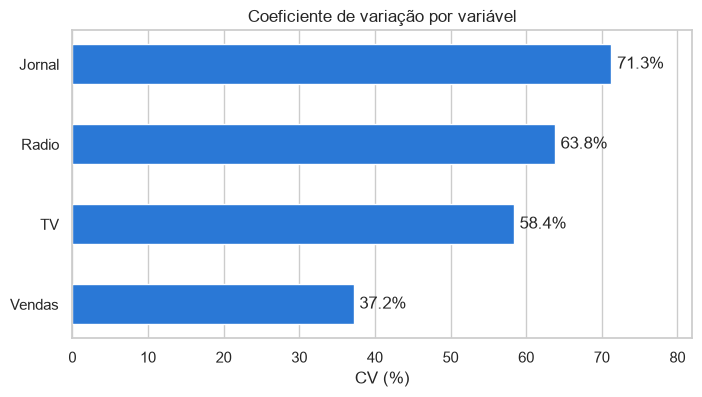

In [28]:
cv = resumo['CV (%)'].sort_values()

plt.figure(figsize=(8, 4))
barras = plt.barh(cv.index, cv.values, color='#2a78d6', height=0.5)
plt.bar_label(barras, fmt='%.1f%%', padding=4)
plt.title('Coeficiente de variação por variável')
plt.xlabel('CV (%)')
plt.xlim(0, cv.max() * 1.15)
plt.grid(axis='y', visible=False)
plt.show()

OBSERVAÇÕES

1. Jornal é a mais dispersa, com 71,3% de CV.
2. Radio é a segunda mais dispersa, com 63,8% de CV.
3. TV vem em terceiro, com 58,4% de CV.
4. Vendas, por sua vez, varia bem menos que os investimentos, com 37,2% de CV.

#### 1.1.6. Distribuição das variáveis

> **Objetivo:** ver o formato da distribuição (histograma) e possíveis outliers (boxplot) de cada variável.

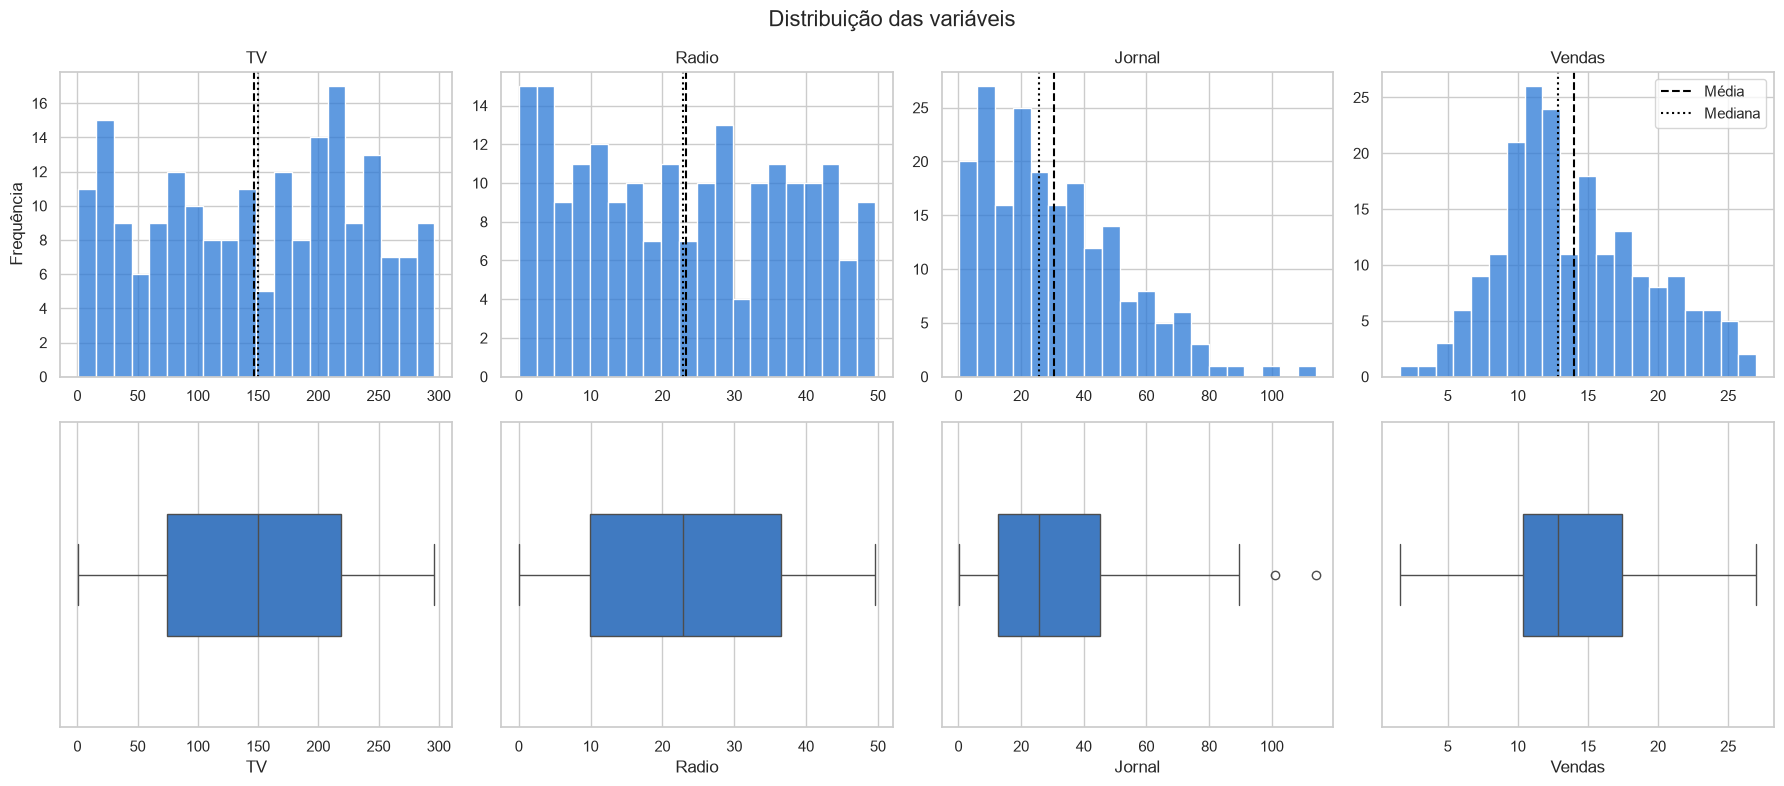

In [29]:
cor = '#2a78d6'
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, coluna in enumerate(propagandas.columns):
    # Histograma com as linhas de média e mediana
    sns.histplot(propagandas[coluna], bins=20, color=cor, ax=axes[0, i])
    axes[0, i].axvline(propagandas[coluna].mean(), color='black', linestyle='--', label='Média')
    axes[0, i].axvline(propagandas[coluna].median(), color='black', linestyle=':', label='Mediana')
    axes[0, i].set_title(coluna)
    axes[0, i].set_xlabel('')
    axes[0, i].set_ylabel('Frequência' if i == 0 else '')

    # Boxplot
    sns.boxplot(x=propagandas[coluna], color=cor, width=0.4, ax=axes[1, i])

axes[0, 3].legend()
fig.suptitle('Distribuição das variáveis', fontsize=16)
plt.tight_layout()
plt.show()

##### Teste de normalidade (Shapiro-Wilk)

> **Objetivo:** testar se cada variável segue uma distribuição normal (H0: os dados são normais; rejeita-se H0 se p-valor < 0,05).

In [42]:
shapiro = pd.DataFrame(
    [stats.shapiro(propagandas[coluna]) for coluna in propagandas.columns],
    index=propagandas.columns,
    columns=['W', 'p-valor']
).sort_values('W', ascending=False)

# Formatação apenas para exibição
tabela_shapiro = shapiro.round({'W': 4})
tabela_shapiro['p-valor'] = shapiro['p-valor'].apply(lambda p: '< 0.0001' if p < 0.0001 else f'{p:.4f}')
tabela_shapiro

,W,p-valor
Vendas,0.9760,0.0017
TV,0.9495,< 0.0001
Radio,0.9440,< 0.0001
Jornal,0.9364,< 0.0001


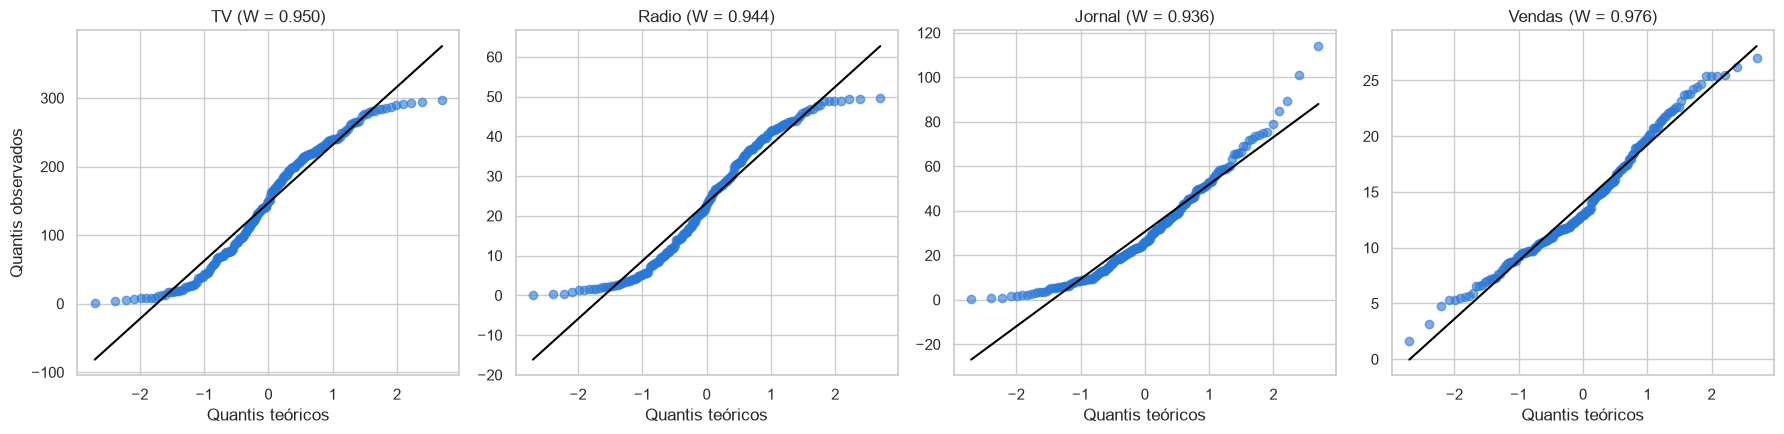

In [43]:
# Q-Q plot: quanto mais próximos da reta os pontos, mais próxima da normal é a distribuição
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, coluna in zip(axes, propagandas.columns):
    stats.probplot(propagandas[coluna], dist='norm', plot=ax)
    ax.get_lines()[0].set(color=cor, alpha=0.6)
    ax.get_lines()[1].set(color='black')
    ax.set_title(f'{coluna} (W = {shapiro.loc[coluna, "W"]:.3f})')
    ax.set_xlabel('Quantis teóricos')
    ax.set_ylabel('Quantis observados' if coluna == 'TV' else '')

plt.tight_layout()
plt.show()

OBSERVAÇÕES

1. TV e Radio apresentam distribuições quase simétricas, porém não normais: não possuem o formato característico de sino, os valores se espalham muito ao longo de toda a faixa.
2. Jornal também não é normal (é a mais distante de uma normal), com assimetria positiva e uma longa cauda à direita.
3. Vendas é a que mais se aproxima de uma distribuição normal, mas não é, com leve assimetria positiva. A maior parte das observações se concentra abaixo da média, porém possui alguns valores altos que puxam a média para cima, fazendo com que a média seja maior que a mediana, formando uma leve cauda à direita.
4. O teste de Shapiro-Wilk rejeitou a normalidade das quatro variáveis a 5% (p < 0,05), o que não impede a regressão, visto que a obrigatoriedade da normalidade se aplica apenas aos resíduos do modelo.

#### 1.1.7. Contagem de outliers pelo IQR

> **Objetivo:** contar e identificar os outliers, isto é, valores abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR.

In [30]:
Q1 = propagandas.quantile(0.25)
Q3 = propagandas.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR
mascara_outliers = (propagandas < limite_inferior) | (propagandas > limite_superior)

print("Outliers por variável:")
print(mascara_outliers.sum())

# Observações com pelo menos um outlier
propagandas[mascara_outliers.any(axis=1)]

Outliers por variável:
TV        0
Radio     0
Jornal    2
Vendas    0
dtype: int64


,TV,Radio,Jornal,Vendas
16,67.8,36.6,114.0,12.5
101,296.4,36.3,100.9,23.8


OBSERVAÇÕES

Somente dois outliers foram encontrados, ambos em Jornal (114,0 e 100,9); eu vou mantê-los porque são plausíveis e poucos.

#### 1.1.8. Relação entre as variáveis

> **Objetivo:** ver se as variáveis (features) se relacionam entre si (indício de multicolinearidade) e ter uma visão geral da relação delas com `Vendas`.

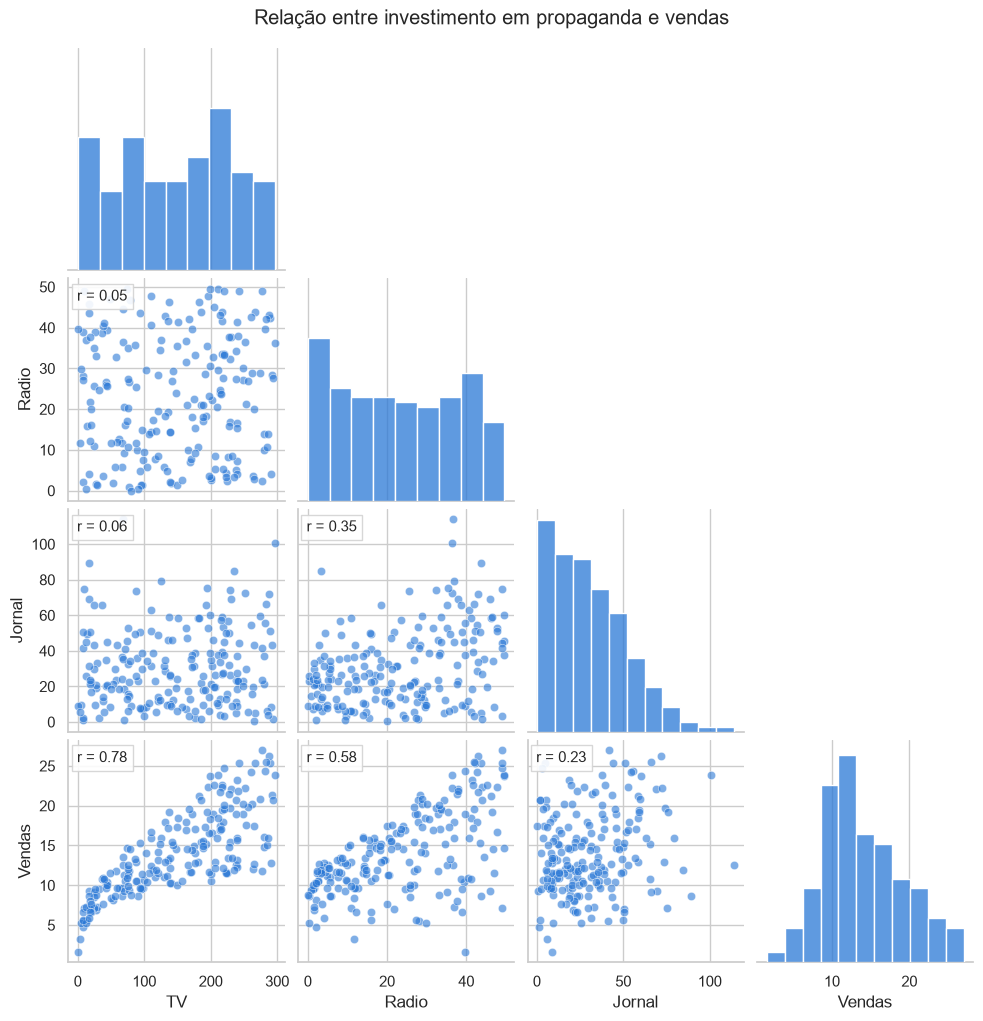

In [39]:
grafico = sns.pairplot(propagandas, corner=True, plot_kws={'color': cor, 'alpha': 0.6}, diag_kws={'color': cor})

# Escreve o coeficiente de correlação de Pearson (r) em cada gráfico de dispersão
def anota_r(x, y, **kwargs):
    r = x.corr(y)
    ax = plt.gca()
    ax.text(0.04, 0.95, f'r = {r:.2f}', transform=ax.transAxes, va='top', fontsize=11,
            bbox={'facecolor': 'white', 'edgecolor': 'lightgray', 'alpha': 0.9})

grafico.map_lower(anota_r)
grafico.figure.suptitle('Relação entre investimento em propaganda e vendas', y=1.02)
plt.show()

OBSERVAÇÕES

1. Vendas sobe com TV e com Radio; já com Jornal a nuvem é bem espalhada.
2. Entre as variáveis (features), quase não há relação; a maior é Jornal x Radio (r = 0,35), um indício inicial de ausência de multicolinearidade forte.

#### 1.1.9. Vendas x variáveis (features)

> **Objetivo:** ver a direção e a força da relação de cada variável (feature) com `Vendas`.

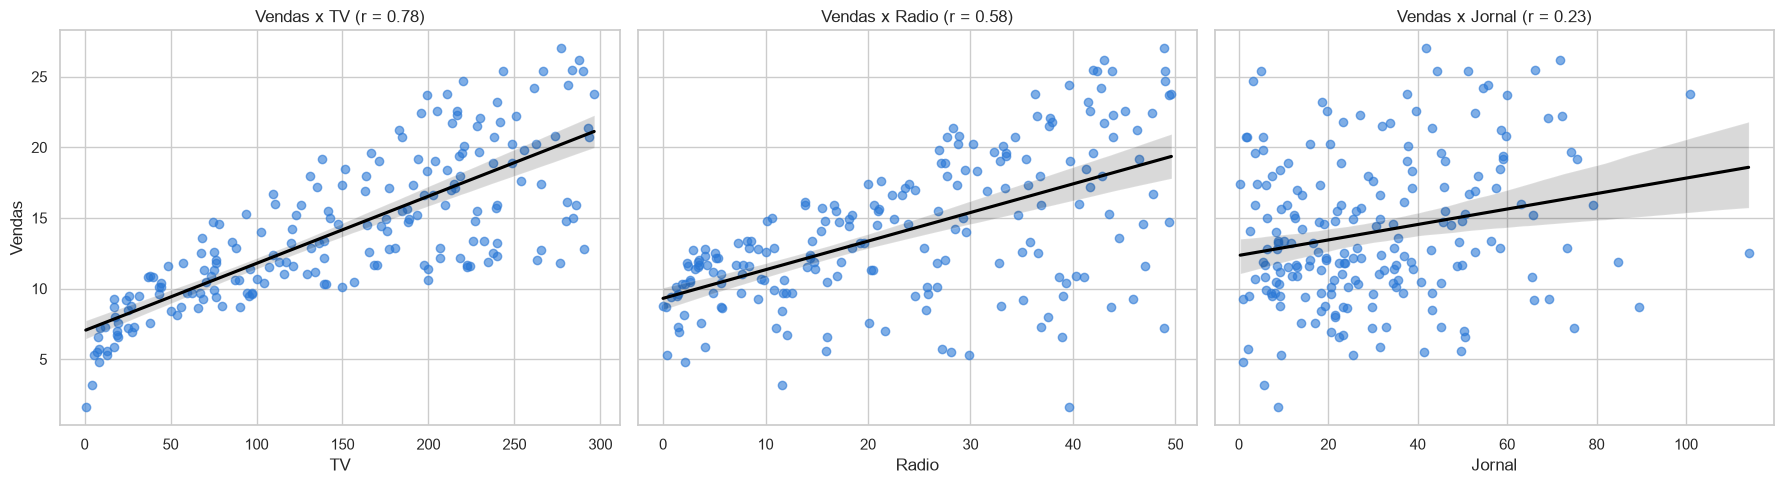

In [ ]:
features = ['TV', 'Radio', 'Jornal']
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, coluna in zip(axes, features):
    sns.regplot(data=propagandas, x=coluna, y='Vendas', ax=ax,
                scatter_kws={'color': cor, 'alpha': 0.6}, line_kws={'color': 'black'})
    r = propagandas[coluna].corr(propagandas['Vendas']) # Coeficiente de correlação de Pearson
    ax.set_title(f'Vendas x {coluna} (r = {r:.2f})')
    ax.set_ylabel('Vendas' if coluna == 'TV' else '')

plt.tight_layout()
plt.show()

OBSERVAÇÕES

1. Vendas x TV: relação mais forte das 3 features (r = 0,78), os pontos ficam mais próximos da reta com pouco investimento e vão se abrindo conforme o investimento aumenta.
2. Vendas x Radio: relação moderada (r = 0,58), os pontos estão relativamente próximos à reta e também se abrem conforme o investimento aumenta.
3. Vendas x Jornal: relação mais fraca (r = 0,23), a nuvem é bem dispersa, a reta quase não ajuda a explicar as vendas.

### 1.2. Correlação e covariância

> **Objetivo:** medir em números a relação entre as variáveis.

#### 1.2.1. Covariância

> **Objetivo:** ver o sentido (sinal) da relação entre cada par; o valor depende da escala das variáveis. Na diagonal está a variância.

In [44]:
propagandas.cov().round(2)

,TV,Radio,Jornal,Vendas
TV,7370.95,69.86,105.92,350.39
Radio,69.86,220.43,114.50,44.64
Jornal,105.92,114.50,474.31,25.94
Vendas,350.39,44.64,25.94,27.22


OBSERVAÇÕES

Todas as covariâncias são positivas, as variáveis tendem a crescer juntas.

#### 1.2.2. Correlação de Pearson

> **Objetivo:** medir a direção e a força da relação **linear** entre cada par, de -1 a 1.

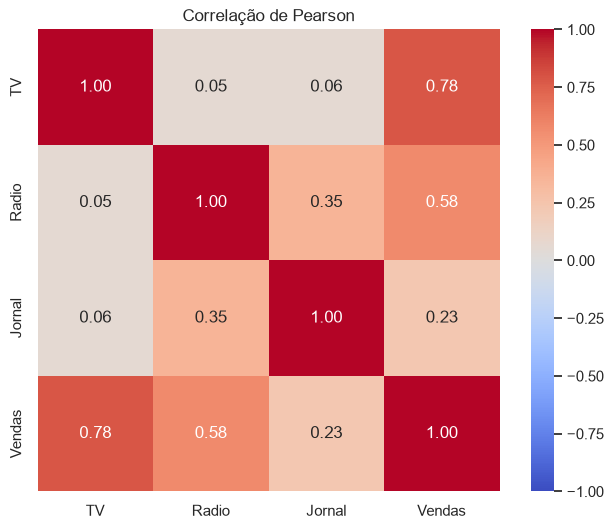

In [45]:
corr_pearson = propagandas.corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlação de Pearson')
plt.show()

OBSERVAÇÕES

Podemos ver na última linha do gráfico (Vendas) que nossas observações iniciais se confirmam (já tínhamos aplicado o método de Pearson). Confirmamos que:

Entre o alvo e as nossas features:
1. Vendas x TV é realmente a correlação mais forte (r = 0,78).
2. Vendas x Radio vem em segundo lugar (r = 0,58).
3. Vendas x Jornal vem por último, com a relação mais fraca entre as features x Vendas (r = 0,23).

Entre as features:
1. Temos uma relação fraca entre Jornal x Radio (r = 0,35), fraca, porém ainda maior do que a relação de Jornal com o alvo (Vendas).

#### 1.2.3. Correlação de Spearman

> **Objetivo:** medir a relação **monotônica** (crescente ou decrescente, mesmo que não seja uma reta) e comparar com Pearson.

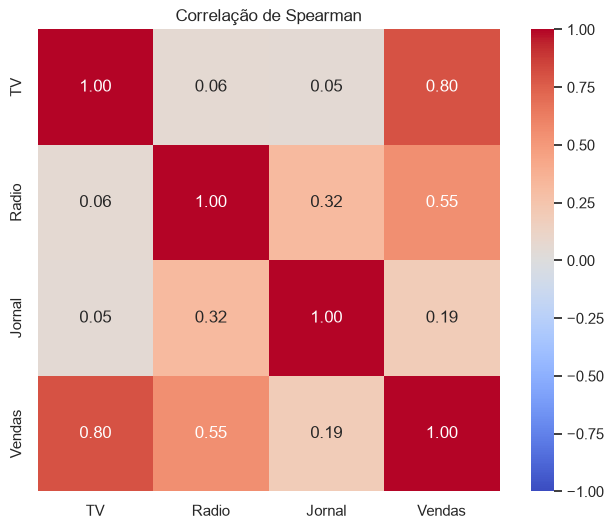

In [46]:
corr_spearman = propagandas.corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlação de Spearman')
plt.show()

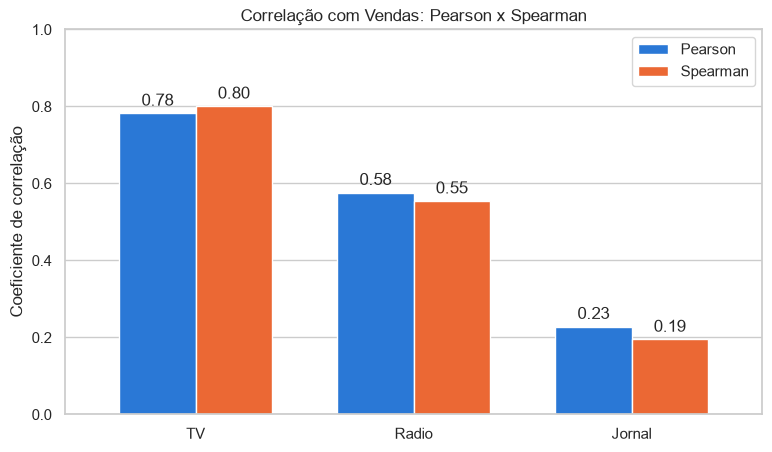

In [47]:
# Correlação de cada preditora com Vendas: Pearson x Spearman
comparacao = pd.DataFrame({
    'Pearson': corr_pearson['Vendas'],
    'Spearman': corr_spearman['Vendas']
}).drop('Vendas')

ax = comparacao.plot.bar(figsize=(9, 5), rot=0, width=0.7, color=['#2a78d6', '#eb6834'])
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.2f', padding=3)
ax.set_title('Correlação com Vendas: Pearson x Spearman')
ax.set_ylabel('Coeficiente de correlação')
ax.set_ylim(0, 1)
ax.grid(axis='x', visible=False)
plt.show()

OBSERVAÇÕES

Com o método de Spearman, nossas observações seguem confirmadas, conforme a seção anterior (1.2.2): a maior relação é Vendas x TV, a segunda maior é Vendas x Radio e, por último, Vendas x Jornal.

A comparação entre Pearson x Spearman mostra valores muito próximos: Vendas x TV subiu um pouco (de 0,78 para 0,80), Radio e Jornal caíram um pouco (0,58 para 0,55 e 0,23 para 0,19, respectivamente).

#### 1.2.4. Teste de hipótese para a correlação

> **Objetivo:** verificar se cada correlação é estatisticamente significativa (H0: correlação = 0; rejeita-se H0 se p-valor < 0,05).

In [48]:
pares = [('TV', 'Vendas'), ('Radio', 'Vendas'), ('Jornal', 'Vendas'),
         ('TV', 'Radio'), ('TV', 'Jornal'), ('Radio', 'Jornal')]

def formata_p(p):
    return '< 0.0001' if p < 0.0001 else f'{p:.4f}'

linhas = []
for a, b in pares:
    r, p_pearson = stats.pearsonr(propagandas[a], propagandas[b])
    rho, p_spearman = stats.spearmanr(propagandas[a], propagandas[b])
    linhas.append({'Par': f'{a} x {b}',
                   'Pearson': round(r, 2), 'p-valor (Pearson)': formata_p(p_pearson),
                   'Spearman': round(rho, 2), 'p-valor (Spearman)': formata_p(p_spearman)})

pd.DataFrame(linhas).set_index('Par')

,Pearson,p-valor (Pearson),Spearman,p-valor (Spearman)
Par,,,,
TV x Vendas,0.78,< 0.0001,0.80,< 0.0001
Radio x Vendas,0.58,< 0.0001,0.55,< 0.0001
Jornal x Vendas,0.23,0.0011,0.19,0.0057
TV x Radio,0.05,0.4408,0.06,0.4299
TV x Jornal,0.06,0.4256,0.05,0.4746
Radio x Jornal,0.35,< 0.0001,0.32,< 0.0001


OBSERVAÇÕES

Significativos (com base no p-valor):
1. Vendas x TV: relação forte (r = 0,78; p < 0,0001).
2. Vendas x Radio: relação moderada (r = 0,58; p < 0,0001).
3. Vendas x Jornal: relação fraca (r = 0,23; p = 0,0011).
4. Radio x Jornal: relação fraca (r = 0,35; p < 0,0001).

Não significativos (p > 0,05):
1. TV x Radio (r = 0,05; p = 0,4408).
2. TV x Jornal (r = 0,06; p = 0,4256).

Vendas x Jornal mostra que a relação pode ser significativa e, ainda assim, fraca. Pelo método de Spearman, as conclusões são as mesmas.

### 1.3. Modelo de regressão

> **Objetivo:** ajustar um modelo de regressão linear múltipla para predizer `Vendas`.

#### 1.3.1. Definição das variáveis

> **Objetivo:** separar o alvo das preditoras e adicionar a constante (intercepto).

In [51]:
# Variável dependente (alvo)
y_prop = propagandas['Vendas']

# Variáveis independentes (preditoras), com a constante para o intercepto
X_prop = sm.add_constant(propagandas[['TV', 'Radio', 'Jornal']])
X_prop.head()

,const,TV,Radio,Jornal
0,1.0,230.1,37.8,69.2
1,1.0,44.5,39.3,45.1
2,1.0,17.2,45.9,69.3
3,1.0,151.5,41.3,58.5
4,1.0,180.8,10.8,58.4


#### 1.3.2. Ajuste do modelo

> **Objetivo:** estimar os coeficientes pelo método dos mínimos quadrados (MQO) e ver o resumo do modelo.

In [52]:
modelo_prop = sm.OLS(y_prop, X_prop).fit()
modelo_prop.summary(title='Modelo de regressão múltipla - Propagandas')

<class 'statsmodels.iolib.summary.Summary'>
"""
                  Modelo de regressão múltipla - Propagandas                  
==============================================================================
Dep. Variable:                 Vendas   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        12:37:54   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
Radio          0.1885      0.009     21.893      0.000       0.172       0.206
Jornal        -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

OBSERVAÇÕES

1. O nosso modelo resultante, com base no R², explica cerca de 90% da variação dos dados, o que inicialmente nos faz acreditar que é um bom modelo regressor.
2. Vemos que a feature Jornal não foi significativa (p = 0,860 > 0,05); TV e Radio, por sua vez, foram significativas (p < 0,001).

#### 1.3.3. Equação do modelo

> **Objetivo:** escrever a equação estimada.

In [53]:
coef = modelo_prop.params

equacao = f"Vendas = {coef['const']:.4f}"
for coluna in ['TV', 'Radio', 'Jornal']:
    sinal = '+' if coef[coluna] >= 0 else '-'
    equacao += f" {sinal} {abs(coef[coluna]):.4f} * {coluna}"
print(equacao)

Vendas = 2.9389 + 0.0458 * TV + 0.1885 * Radio - 0.0010 * Jornal


#### 1.3.4. Valores observados x previstos

> **Objetivo:** ver o quanto as previsões se aproximam das vendas reais; quanto mais perto da linha, melhor.

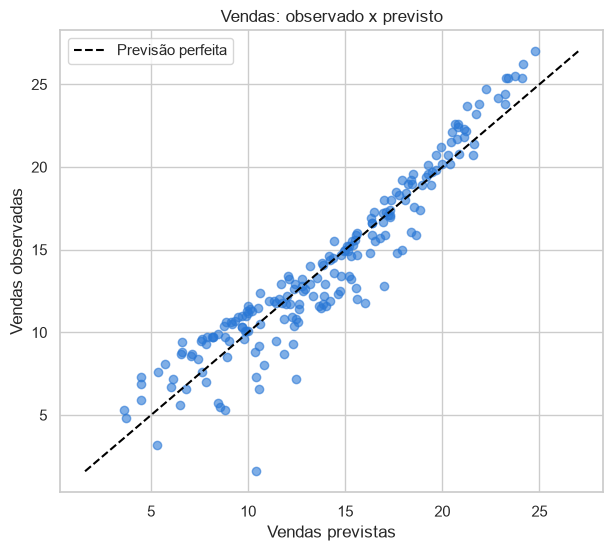

In [55]:
previstos = modelo_prop.fittedvalues

plt.figure(figsize=(7, 6))
plt.scatter(previstos, y_prop, color='#2a78d6', alpha=0.6)
limites = [min(previstos.min(), y_prop.min()), max(previstos.max(), y_prop.max())]
plt.plot(limites, limites, color='black', linestyle='--', label='Previsão perfeita')
plt.title('Vendas: observado x previsto')
plt.xlabel('Vendas previstas')
plt.ylabel('Vendas observadas')
plt.legend()
plt.show()

OBSERVAÇÕES

1. Os pontos acompanham bem a reta, então, no geral, o modelo acerta bem as vendas.
2. Nas pontas (previsões baixas e mais altas), a maioria fica acima da linha, o que me parece um leve underfitting nos edge cases: o modelo não capta toda a curvatura dos dados. Vamos verificar mais na análise de resíduos.
3. Um ponto foge bastante, a menor venda (1,6), com previsão perto de 10.

### 1.4. Análise de resíduos

> **Objetivo:** verificar se o modelo atende às suposições da regressão linear.

#### 1.4.1. Resíduos x valores ajustados

> **Objetivo:** ver se os resíduos se espalham ao acaso em torno de zero, sem curva (linearidade) e sem funil (variância constante).

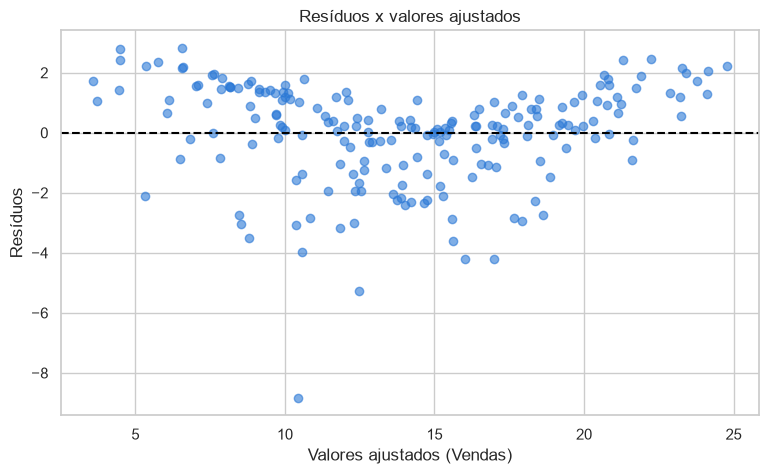

In [56]:
residuos = modelo_prop.resid
ajustados = modelo_prop.fittedvalues

plt.figure(figsize=(9, 5))
plt.scatter(ajustados, residuos, color=cor, alpha=0.6)
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Resíduos x valores ajustados')
plt.xlabel('Valores ajustados (Vendas)')
plt.ylabel('Resíduos')
plt.show()

OBSERVAÇÕES

Conseguimos ver que os resíduos não se espalham de forma completamente aleatória; um formato de U é bem visível: mais positivos nas pontas e mais negativos no meio. Isso indica não linearidade e confirma o underfitting que notei na seção 1.3.4.

#### 1.4.2. Homocedasticidade (Breusch-Pagan)

> **Objetivo:** testar se a variância dos resíduos é constante (H0: homocedasticidade; rejeita-se H0 se p-valor < 0,05).

In [59]:
bp = het_breuschpagan(residuos, X_prop)

pd.DataFrame({'Estatística LM': [round(bp[0], 4)], 'p-valor': [formata_p(bp[1])]}, index=['Breusch-Pagan'])

,Estatística LM,p-valor
Breusch-Pagan,5.1329,0.1623


OBSERVAÇÕES

Utilizando o método Breusch-Pagan, temos p = 0,1623 > 0,05, então não se rejeita a homocedasticidade.

#### 1.4.3. Normalidade dos resíduos

> **Objetivo:** ver se os resíduos seguem uma distribuição normal (Shapiro-Wilk, H0: os resíduos são normais; rejeita-se H0 se p-valor < 0,05).

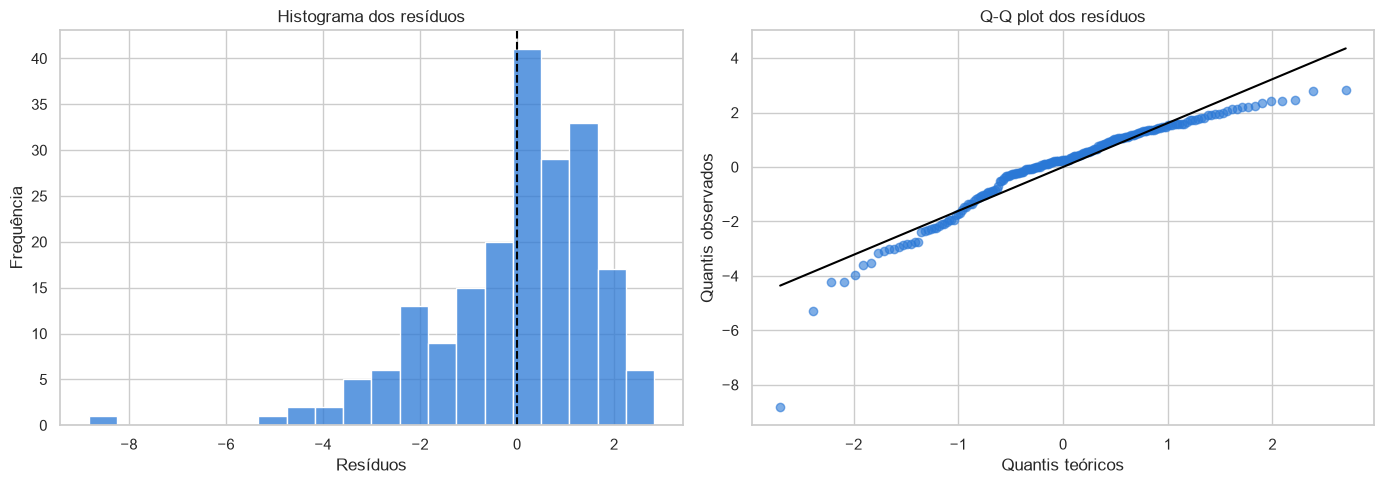

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma
sns.histplot(residuos, bins=20, color=cor, ax=axes[0])
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_title('Histograma dos resíduos')
axes[0].set_xlabel('Resíduos')
axes[0].set_ylabel('Frequência')

# Q-Q plot
stats.probplot(residuos, dist='norm', plot=axes[1])
axes[1].get_lines()[0].set(color=cor, alpha=0.6)
axes[1].get_lines()[1].set(color='black')
axes[1].set_title('Q-Q plot dos resíduos')
axes[1].set_xlabel('Quantis teóricos')
axes[1].set_ylabel('Quantis observados')

plt.tight_layout()
plt.show()

In [61]:
W, p_shapiro = stats.shapiro(residuos)

pd.DataFrame({'W': [round(W, 4)], 'p-valor': [formata_p(p_shapiro)]}, index=['Shapiro-Wilk'])

,W,p-valor
Shapiro-Wilk,0.9177,< 0.0001


OBSERVAÇÕES

Os resíduos não são normais: o histograma tem cauda longa à esquerda, e no Q-Q plot os pontos ficam abaixo da reta nas duas pontas.

#### 1.4.4. Resíduos padronizados (outliers)

> **Objetivo:** identificar as observações que o modelo erra muito (resíduo padronizado acima de 3 ou abaixo de -3).

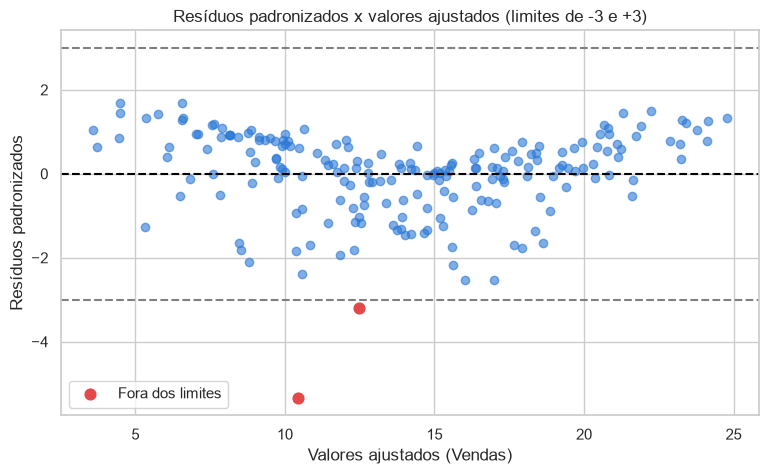

In [63]:
influencia = modelo_prop.get_influence()
residuos_padronizados = pd.Series(influencia.resid_studentized_internal, index=propagandas.index)
extremos = residuos_padronizados.abs() > 3

plt.figure(figsize=(9, 5))
plt.scatter(ajustados[~extremos], residuos_padronizados[~extremos], color=cor, alpha=0.6)
plt.scatter(ajustados[extremos], residuos_padronizados[extremos], color='#e34948', s=60, label='Fora dos limites')
plt.axhline(y=0, color='black', linestyle='--')
plt.axhline(y=3, color='gray', linestyle='--')
plt.axhline(y=-3, color='gray', linestyle='--')
plt.title('Resíduos padronizados x valores ajustados (limites de -3 e +3)')
plt.xlabel('Valores ajustados (Vendas)')
plt.ylabel('Resíduos padronizados')
plt.legend()
plt.show()

In [66]:
# Observações fora dos limites (resíduo = real - previsto)
tabela_extremos = propagandas[extremos].rename(columns={'Vendas': 'Vendas (real)'})
tabela_extremos['Vendas (prevista)'] = ajustados[extremos].round(2)
tabela_extremos['Resíduo'] = residuos[extremos].round(2)
tabela_extremos['Resíduo padronizado'] = residuos_padronizados[extremos].round(2)
tabela_extremos.sort_values('Resíduo padronizado')

,TV,Radio,Jornal,Vendas (real),Vendas (prevista),Resíduo,Resíduo padronizado
130,0.7,39.6,8.7,1.6,10.43,-8.83,-5.34
5,8.7,48.9,75.0,7.2,12.48,-5.28,-3.21


OBSERVAÇÕES

Duas observações ficaram fora dos limites de +3 e -3:
1. Sinal negativo: o modelo previu mais do que vendeu de verdade.
2. Linha 130: o modelo esperava 10,43 e só vendeu 1,6.

O que as duas têm em comum?

Olhando os investimentos, vemos que, com o investimento em Radio alto e o investimento em TV baixo, o modelo soma o efeito do Radio inteiro e espera boas vendas, mas elas não vieram. Uma possível explicação para isso é o investimento em Radio render menos sem investimento em TV, mas, como temos pouquíssimas observações, isso é apenas uma hipótese, não confirmada.